# ДЗ 1. Рекомендации CD и винила: пять моделей с нуля

## Данные

**Датасет:** Amazon Reviews 2023, категория **CDs_and_Vinyl** (McAuley Lab, UCSD).
Hou et al., *Bridging Language and Items for Retrieval and Recommendation*, 2024, [arXiv:2403.03952](https://arxiv.org/abs/2403.03952).

- Сайт датасета: https://amazon-reviews-2023.github.io/
- Hugging Face: https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023

**Как получить.** Скачать два файла категории CDs_and_Vinyl и положить в папку `data/`:
- `data/CDs_and_Vinyl.csv` — оценки (rating only, 0-core): https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/resolve/main/benchmark/0core/rating_only/CDs_and_Vinyl.csv
- `data/meta_CDs_and_Vinyl.jsonl` — метаданные товаров (распакованный `meta_CDs_and_Vinyl.jsonl.gz`): https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023/tree/main/raw/meta_categories

**Поля взаимодействий:**
| Поле | Смысл |
|---|---|
| `user_id` | анонимный идентификатор пользователя |
| `parent_asin` | идентификатор товара (альбома; разные издания объединены) |
| `rating` | оценка в отзыве, 1–5 |
| `timestamp` | время отзыва, мс с 1970 г. |

Взаимодействие — пользователь оставил отзыв с оценкой на товар; считаем это фактом покупки/прослушивания.

**Метаданные** (`meta_CDs_and_Vinyl.jsonl`): жанры (`categories`), артист и формат (`store`, например `"SWV Format: Audio CD"`), лейбл и дата релиза (`details`), цена, описание. Поля `average_rating`, `rating_number` и `bought_together` не используем: это агрегаты на момент сбора датасета (2023), то есть утечка из будущего.

**Что рекомендуем:** персональный top-10 альбомов (CD/винил), которые пользователь ещё не оценивал.
**Что релевантно:** товар, который пользователь оценил на **≥ 4** в будущем периоде (validation/test).

**Объём:** исходно 4 772 071 взаимодействие, 1 754 118 пользователей, 701 673 товара; после итеративного 10-core — 519 283 взаимодействия, 22 170 пользователей, 20 089 товаров.

## Запуск

1. `pip install -r requirements.txt`. Для GPU PyTorch с CUDA ставится отдельно под свою видеокарту: https://pytorch.org/get-started/locally/
2. Положить данные в `data/`, как описано выше.
3. Kernel → Restart & Run All. EASE, iALS и FM считаются на GPU, если он есть, иначе на CPU (`torch.cuda.is_available()`).
   На CPU подбор гиперпараметров идёт долго. Чтобы проверить только итоговую таблицу, достаточно выполнить разделы «EDA», «Протокол оценки» и «Сравнение на test».

Случайность зафиксирована: `SEED = 42` в ноутбуке, `seed=42` по умолчанию в iALS и FM.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
from time import perf_counter
from models.utils import k_core, build_matrix, build_ground_truth, evaluate, topk_from_scores,\
    matrix_with_maps
%load_ext autoreload
%autoreload 2

SEED = 42
np.random.seed(SEED)
K_CORE = 10

## EDA и подготовка

In [2]:
pd.read_csv("data/CDs_and_Vinyl.csv", nrows=5)

,user_id,parent_asin,rating,timestamp
0,AGKASBHYZPGTEPO6LWZPVJWB2BVA,B00IKM5N02,3.0,1452649885000
1,AGKASBHYZPGTEPO6LWZPVJWB2BVA,B008XNPN0S,5.0,1452650764000
2,AGKASBHYZPGTEPO6LWZPVJWB2BVA,B002MW50JA,5.0,1452650777000
3,AEVWAM3YWN5URJVJIZZ6XPD2MKIA,B00006JKCM,3.0,1164036864000
4,AFWHJ6O3PV4JC7PVOJH6CPULO2KQ,B000002AGY,5.0,1358286606000


In [3]:
df = pd.read_csv("data/CDs_and_Vinyl.csv")
n_before = len(df)
df = df.dropna()
df = df.sort_values("timestamp").drop_duplicates(["user_id", "parent_asin"], keep="last")
print(f"Было строк: {n_before}, стало: {len(df)}, удалено: {n_before - len(df)}")

Было строк: 4772071, стало: 4772071, удалено: 0


Пропусков и повторных оценок одной пары (user, item) нет.

In [4]:
def describe(d):
    n_users = d["user_id"].nunique()
    n_items = d["parent_asin"].nunique()
    n_rows = len(d)
    sparsity = 1 - n_rows / (n_users * n_items)
    print(f"Взаимодействий: {n_rows:,}")
    print(f"Пользователей:  {n_users:,}")
    print(f"Товаров:        {n_items:,}")
    print(f"Разреженность:  {sparsity:.6f}")
    print(f"Оценок на пользователя в среднем: {n_rows / n_users:.2f}")
    print(f"Оценок на товар в среднем:        {n_rows / n_items:.2f}")

describe(df)

Взаимодействий: 4,772,071
Пользователей:  1,754,118
Товаров:        701,673
Разреженность:  0.999996
Оценок на пользователя в среднем: 2.72
Оценок на товар в среднем:        6.80


In [5]:
print(df["rating"].value_counts(normalize=True).sort_index())

rating
1.0    0.038770
2.0    0.029095
3.0    0.058746
4.0    0.137701
5.0    0.735689
Name: proportion, dtype: float64


74% оценок — пятёрки, низких оценок очень мало. Поэтому решаем задачу как implicit: факт отзыва = взаимодействие, а релевантным в будущем периоде считаем товар с оценкой ≥ 4.

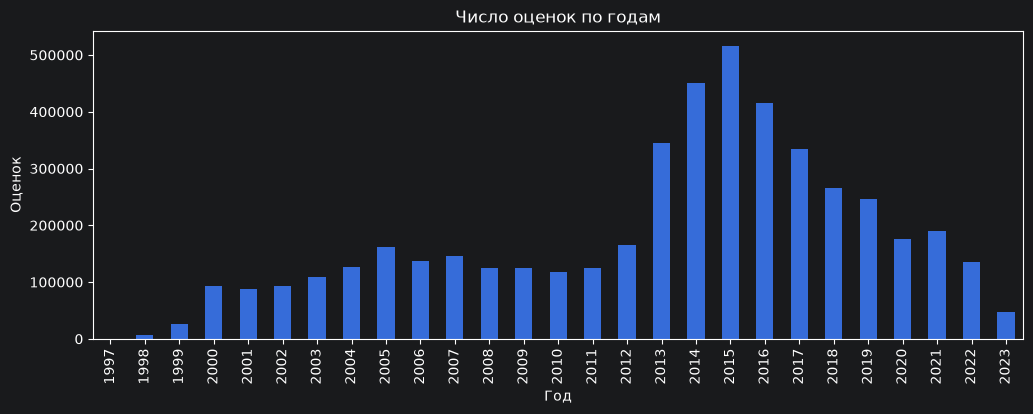

In [6]:
df["dt"] = pd.to_datetime(df["timestamp"], unit="ms")
df["dt"].dt.year.value_counts().sort_index().plot(kind="bar", figsize=(12, 4))
plt.title("Число оценок по годам")
plt.xlabel("Год")
plt.ylabel("Оценок")
plt.show()

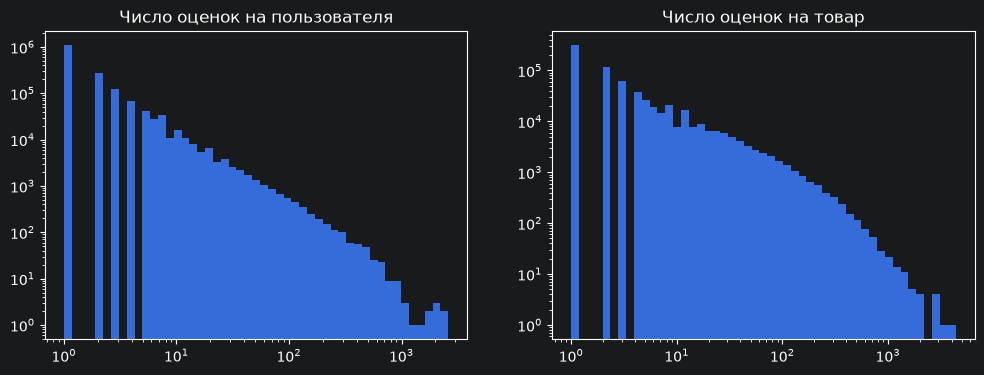

Пользователей с 1 оценкой: 63.0%, с ≥5: 10.3%
Товаров с 1 оценкой: 45.2%, с ≥5: 23.9%


In [7]:
user_cnt = df["user_id"].value_counts()
item_cnt = df["parent_asin"].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, cnt, name in [(axes[0], user_cnt, "пользователя"), (axes[1], item_cnt, "товар")]:
    bins = np.logspace(0, np.log10(cnt.max()), 50)
    ax.hist(cnt, bins=bins)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f"Число оценок на {name}")
plt.show()

for cnt, name in [(user_cnt, "Пользователей"), (item_cnt, "Товаров")]:
    print(f"{name} с 1 оценкой: {(cnt == 1).mean():.1%}, с ≥5: {(cnt >= 5).mean():.1%}")

Много товаров и пользователей с 1 оценкой. Такие пользователи не бывают одновременно в трейне и тесте, а товары по одной оценке очень слабо связаны с другими товарами, поэтому будем использовать итеративный k_core, чтобы оставить пользователей и товаров с большим числом оценок, то есть о предпочтениях и сути которых мы можем что-то сказать

In [8]:
rows = []
for k in [3, 5, 10]:
    d = k_core(df, k, k, verbose=False)
    rows.append({
        "k": k,
        "взаимодействий": len(d),
        "пользователей": d["user_id"].nunique(),
        "товаров": d["parent_asin"].nunique(),
    })
pd.DataFrame(rows)

,k,взаимодействий,пользователей,товаров
0,3,2526168,318603,197027
1,5,1552764,123876,89370
2,10,519283,22170,20089


Видим, что k = 3 выходит за ограничение по взаимодействиям, а k = 5 будет много для EASE: ~ (9 * 10^4) * (9 * 10^4) * 4 байта ~ 32 гигабайт, а с учетом обращения матрицы это точно выйдет за пределы RAM. k = 10 соответствует (4 * 10^8) * 4 ~ 1,6 гигабайта, что укладывается в RAM

In [9]:
data = k_core(df, K_CORE, K_CORE)
describe(data)

Итерация 1: 974,024 строк
Итерация 2: 615,702 строк
Итерация 3: 549,675 строк
Итерация 4: 530,419 строк
Итерация 5: 523,495 строк
Итерация 6: 520,692 строк
Итерация 7: 519,839 строк
Итерация 8: 519,454 строк
Итерация 9: 519,346 строк
Итерация 10: 519,283 строк
Итерация 11: 519,283 строк
Взаимодействий: 519,283
Пользователей:  22,170
Товаров:        20,089
Разреженность:  0.998834
Оценок на пользователя в среднем: 23.42
Оценок на товар в среднем:        25.85


### Метаданные
Загружаем метаданные только для товаров, оставшихся после k-core. Для FM нужны жанры (`categories`), артист и формат (оба из поля `store`, например `"Pink Floyd Format: Audio CD"`).

Товаров с метаданными: 20,089 из 20,089
Есть хотя бы один жанр: 100.0%, жанров на товар в среднем: 2.39
Есть артист: 100.0%, есть формат: 99.4%
Уникальных жанров: 374, артистов: 6,043


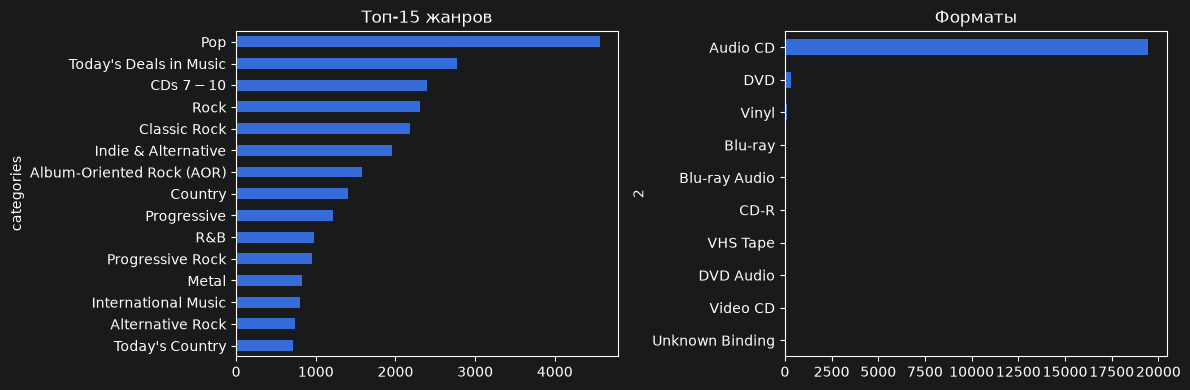

In [10]:
from models.fm import load_meta

meta = load_meta("data/meta_CDs_and_Vinyl.jsonl", set(data["parent_asin"]))
print(f"Товаров с метаданными: {meta['parent_asin'].nunique():,} из {data['parent_asin'].nunique():,}")

cats = meta["categories"].apply(lambda c: [x for x in c if x != "CDs & Vinyl"] if isinstance(c, list) else [])
store = meta["store"].apply(lambda s: s if isinstance(s, str) else "")
artist = store.str.partition("Format:")[0].str.strip()
fmt = store.str.partition("Format:")[2].str.strip()

print(f"Есть хотя бы один жанр: {(cats.str.len() > 0).mean():.1%}, жанров на товар в среднем: {cats.str.len().mean():.2f}")
print(f"Есть артист: {(artist != '').mean():.1%}, есть формат: {(fmt != '').mean():.1%}")
print(f"Уникальных жанров: {cats.explode().nunique():,}, артистов: {artist[artist != ''].nunique():,}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cats.explode().value_counts().head(15).plot(kind="barh", ax=axes[0], title="Топ-15 жанров")
fmt[fmt != ""].value_counts().head(10).plot(kind="barh", ax=axes[1], title="Форматы")
for ax in axes:
    ax.invert_yaxis()
plt.tight_layout()
plt.show()

Метаданные есть у всех 20 089 товаров: жанр у 100% (в среднем 2.4 на товар, 374 разных), артист у 100% (6 043 разных), формат у 99.4%. Почти всё — Audio CD, винила и DVD единицы, так что формат почти ничего не различает. Среди категорий есть служебные категории магазина: «Today's Deals in Music» и ценовая «CDs $7 - $10» (на графике знаки $ съел matplotlib).

Жанры, артист и формат описывают сам альбом и не меняются со временем, то есть известны в момент рекомендации. Цену, описание и лейбл не берём: цена снята на 2023 год, а описание — длинный текст, его надо отдельно обрабатывать.

## Протокол оценки

In [11]:
t1, t2 = data["timestamp"].quantile([0.8, 0.9])
train = data[data["timestamp"] < t1]
val = data[(data["timestamp"] >= t1) & (data["timestamp"] < t2)]
test = data[data["timestamp"] >= t2]
train_val = data[data["timestamp"] < t2]

for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name}: {len(part):,} строк, "
          f"{pd.to_datetime(part['timestamp'].min(), unit='ms').date()} — "
          f"{pd.to_datetime(part['timestamp'].max(), unit='ms').date()}")

train: 415,426 строк, 1998-04-30 — 2016-10-18
val: 51,928 строк, 2016-10-18 — 2018-09-09
test: 51,929 строк, 2018-09-09 — 2023-08-04


Большой тестовый период(с 18 по 23 год), потому что как видно из графика после 2015 начинается спад интереса к винилу и cd

In [12]:
X_tr, u2i_tr, i2i_tr = build_matrix(train)
gt_val = build_ground_truth(val, u2i_tr, i2i_tr)

X_tv, u2i_tv, i2i_tv = build_matrix(train_val)
gt_test = build_ground_truth(test, u2i_tv, i2i_tv)

print(f"X_tr: {X_tr.shape}, пользователей в оценке на val: {len(gt_val):,}")
print(f"X_tv: {X_tv.shape}, пользователей в оценке на test: {len(gt_test):,}")

X_tr: (20049, 18823), пользователей в оценке на val: 5,441
X_tv: (21301, 19527), пользователей в оценке на test: 4,734


- Разбиение глобальное по времени: train — первые 80% взаимодействий, val — следующие 10%, test — последние 10%.
- Гиперпараметры подбираем: обучение на train, оценка на val. Финал: обучаем на train + val с выбранными параметрами, оцениваем на test.
- Оцениваем пользователей, у которых в val/test есть хотя бы один товар с оценкой ≥ 4. Порог одинаковый для всех моделей, кастомный таргет в п. 5 его не меняет.
- Новые пользователи (которых нет в train) не оцениваются. Новые товары выкидываем из ground truth: модели их всё равно не могут порекомендовать.
- Кандидаты — все товары из train, кроме тех, что пользователь уже оценил в train (повторно альбом не советуем).
- Для всех моделей одни и те же разбиения, пользователи, кандидаты и функция `evaluate` из `models/utils.py`.

В качестве основной метрики берем NDCG@10, потому что пользователь обычно смотрит начало списка, и поставить правильный товар наверх ценнее, чем вниз. В качестве вспомогательной Recall@10: какая доля того, что пользователь реально оценил хорошо, попала в топ-10.

In [13]:
from models.popularity import Popularity

pop = Popularity().fit(X_tr)
evaluate(pop, X_tr, gt_val)

{'Recall@10': np.float64(0.0012995327864564518),
 'NDCG@10': np.float64(0.0008338904106552739)}

Популярные предложения дают Recall не намного лучше случайного: если бы предлагали случайно, то, так как товаров около 20 тысяч, то Recall@10 = 10/20 тысяч, то есть 0.0005. Убедимся что ошибки в коде нет,посчитав популярность по validation:

In [14]:
class FixedScores:
    def __init__(self, scores):
        self.scores = scores

    def predict_scores(self, users):
        return np.tile(self.scores, (len(users), 1))
val_pop = np.zeros(X_tr.shape[1])
for items in gt_val.values():
    for i in items:
        val_pop[i] += 1
evaluate(FixedScores(val_pop), X_tr, gt_val)

{'Recall@10': np.float64(0.021615044944860322),
 'NDCG@10': np.float64(0.014515266387775975)}

Видим, что подсмотрев в будущее, Recall становится ~ в 20 раз лучше, значит ошибки в коде нет и низкий Recall на популярных предложениях обусловлен спецификой темы: у любителей cd и винила вкусы довольно уникальные, поэтому без персонализированных моделей метрики будут примерно такими

Проверим гипотезу что вкусы меняются со временем, обучив популярную модель по свежей части трейна, а не по всему

In [15]:
for frac in [0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.2, 0.5, 1.0]:
    recent = train[train["timestamp"] >= train["timestamp"].quantile(1 - frac)]
    pop = Popularity().fit(matrix_with_maps(recent, u2i_tr, i2i_tr))
    print(frac, evaluate(pop, X_tr, gt_val))

0.001 {'Recall@10': np.float64(0.00735508347230745), 'NDCG@10': np.float64(0.006023284605568379)}
0.002 {'Recall@10': np.float64(0.011204970744000233), 'NDCG@10': np.float64(0.008279204942346805)}
0.005 {'Recall@10': np.float64(0.014382719558852976), 'NDCG@10': np.float64(0.010514601714853904)}
0.01 {'Recall@10': np.float64(0.012555208003977268), 'NDCG@10': np.float64(0.009421812441694547)}
0.02 {'Recall@10': np.float64(0.009580217531629806), 'NDCG@10': np.float64(0.008078446192424824)}
0.05 {'Recall@10': np.float64(0.012750271585293365), 'NDCG@10': np.float64(0.008698541695426632)}
0.1 {'Recall@10': np.float64(0.009517095097595994), 'NDCG@10': np.float64(0.008142606825934092)}
0.2 {'Recall@10': np.float64(0.008840366022145885), 'NDCG@10': np.float64(0.007637090282989316)}
0.5 {'Recall@10': np.float64(0.0071972083990707435), 'NDCG@10': np.float64(0.006011562903211292)}
1.0 {'Recall@10': np.float64(0.0012995327864564518), 'NDCG@10': np.float64(0.0008338904106552739)}


Действительно, NDCG сильно лучше на свежей части трейна. Видно что максимум приходится на frac = 0.005 и составляет 0.0105, дальше взаимодействий слишком мало и шум вносит слишком большую погрешность.
В качестве бейзлайна берем Popularity с frac = 0.005, а основную метрику - NDCG@10, вспомогательная - Recall@10

## Модели

### 1. Item-based kNN
Сходство товаров — косинус между столбцами $X$ (векторами товаров по пользователям):
$$\text{sim}(i, j) = \frac{x_i^\top x_j}{\|x_i\|\,\|x_j\|}$$
Для каждого товара оставляем $k$ самых похожих $N_k(i)$, скор — сумма сходств с товарами из истории:
$$\text{score}(u, i) = \sum_{j \in I_u \cap N_k(i)} \text{sim}(i, j)$$
Сетка: $k \in \{20, 50, 100, 200, 400\}$.

In [16]:
from models.item_knn import ItemKNN

for k in [20, 50, 100, 200, 400]:
    knn = ItemKNN(k=k).fit(X_tr)
    print(k, evaluate(knn, X_tr, gt_val))

20 {'Recall@10': np.float64(0.026043423132538608), 'NDCG@10': np.float64(0.02146767489824958)}
50 {'Recall@10': np.float64(0.026924374945832098), 'NDCG@10': np.float64(0.021718623453228097)}
100 {'Recall@10': np.float64(0.02744666222902741), 'NDCG@10': np.float64(0.0218433611843898)}
200 {'Recall@10': np.float64(0.027649770110011587), 'NDCG@10': np.float64(0.021909869674582437)}
400 {'Recall@10': np.float64(0.027675292675291313), 'NDCG@10': np.float64(0.021641858542021233)}


гиперпараметр k = 200 дает оптимальный NDCG = 0.0219, что примерно в 2 раза выше бейзлайна

### 2. iALS
Фидбэк неявный: $p_{ui} = 1$, если пользователь оценил товар, иначе 0. Уверенность $c_{ui} = 1 + \alpha$ для наблюдаемых пар и 1 для остальных.
$$L = \sum_{u,i} c_{ui}\,(p_{ui} - x_u^\top y_i)^2 + \lambda(\|X\|^2 + \|Y\|^2)$$
Попеременно фиксируем $Y$ и решаем для $X$ в закрытом виде, потом наоборот (10 итераций):
$$x_u = \Big(Y^\top Y + \alpha \sum_{i \in I_u} y_i y_i^\top + \lambda I\Big)^{-1} (1 + \alpha) \sum_{i \in I_u} y_i$$
Сетка: сначала $\alpha \in \{50, 100, 200\}$, $\lambda \in \{100, 300, 1000\}$ при 256 факторах, потом factors $\in \{64, 128, 256, 512\}$.

In [17]:
from models.ials import IALS

for alpha in [50, 100, 200]:
    for reg in [100, 300, 1000]:
        start = perf_counter()
        als = IALS(factors=256, alpha=alpha, reg=reg).fit(X_tr)
        print(alpha, reg, evaluate(als, X_tr, gt_val), f"{perf_counter() - start:.1f} c")

50 100 {'Recall@10': np.float64(0.0314034086320702), 'NDCG@10': np.float64(0.025457858994435364)} 9.2 c
50 300 {'Recall@10': np.float64(0.025985051043058108), 'NDCG@10': np.float64(0.022297988943268444)} 9.0 c
50 1000 {'Recall@10': np.float64(0.008508999663237177), 'NDCG@10': np.float64(0.0075802046009314245)} 8.7 c
100 100 {'Recall@10': np.float64(0.031706517631232084), 'NDCG@10': np.float64(0.025382405102854454)} 8.7 c
100 300 {'Recall@10': np.float64(0.03245634539524003), 'NDCG@10': np.float64(0.025789388730139483)} 8.7 c
100 1000 {'Recall@10': np.float64(0.01730515717138213), 'NDCG@10': np.float64(0.014402839873982512)} 8.7 c
200 100 {'Recall@10': np.float64(0.03145850543127342), 'NDCG@10': np.float64(0.02474743836212994)} 8.7 c
200 300 {'Recall@10': np.float64(0.03274389753380567), 'NDCG@10': np.float64(0.025634263355956546)} 8.7 c
200 1000 {'Recall@10': np.float64(0.02519422227606235), 'NDCG@10': np.float64(0.020793952946311988)} 8.7 c


Оптимальная пара alpha = 100, lambda = 300

In [18]:
for factors in [64, 128, 256, 512]:
    start = perf_counter()
    als = IALS(factors=factors, alpha=100, reg=300).fit(X_tr)
    print(factors, evaluate(als, X_tr, gt_val), f"{perf_counter() - start:.1f} с")

64 {'Recall@10': np.float64(0.026834052444409326), 'NDCG@10': np.float64(0.021839536779528806)} 2.1 с
128 {'Recall@10': np.float64(0.027997838128932293), 'NDCG@10': np.float64(0.022737454863787646)} 3.3 с
256 {'Recall@10': np.float64(0.03245634539524003), 'NDCG@10': np.float64(0.025789388730139483)} 8.8 с
512 {'Recall@10': np.float64(0.030946420318748866), 'NDCG@10': np.float64(0.025076664834320594)} 27.0 с


Оптимальная размерность factors = 256

### 3. EASE
Сетка: $\lambda \in \{10, 20, 50, 200, 500, 1000, 3000\}$, формула ниже.

In [19]:
from models.ease import EASE

for reg in [10, 20, 50, 200, 500, 1000, 3000]:
    start = perf_counter()
    ease = EASE(reg=reg).fit(X_tr)
    print(reg, evaluate(ease, X_tr, gt_val), f"{perf_counter() - start:.1f} с")

10 {'Recall@10': np.float64(0.02662216444748649), 'NDCG@10': np.float64(0.022176395615957124)} 11.5 с
20 {'Recall@10': np.float64(0.027632842486174144), 'NDCG@10': np.float64(0.022757602367102503)} 11.4 с
50 {'Recall@10': np.float64(0.028494025176327747), 'NDCG@10': np.float64(0.023158162199818377)} 11.0 с
200 {'Recall@10': np.float64(0.027942994697240715), 'NDCG@10': np.float64(0.02248568373715709)} 11.2 с
500 {'Recall@10': np.float64(0.025882671380813137), 'NDCG@10': np.float64(0.021434505739196932)} 11.2 с
1000 {'Recall@10': np.float64(0.0243884190398961), 'NDCG@10': np.float64(0.02083569725321515)} 11.1 с
3000 {'Recall@10': np.float64(0.02273079761925353), 'NDCG@10': np.float64(0.019600348687273794)} 11.1 с


Каждый товар из истории пользователя «голосует» за кандидата с силой $B_{ji}$, скор — сумма голосов:
$\text{score}_u = X_u B$. Веса подбираются так, чтобы по остальным оценкам пользователя
восстанавливать, что он оценил (диагональ обнуляем, чтобы товар не предсказывал сам себя):

$$\min_{B,\ \text{diag}(B)=0} \|X - XB\|^2 + \lambda\|B\|^2 \quad\Rightarrow\quad
P = (X^\top X + \lambda I)^{-1},\ \ B_{ij} = -\frac{P_{ij}}{P_{jj}}$$

В отличие от KNN, товары, которые оценивают одни и те же люди, не засчитываются несколько раз.
Лучший NDCG@10 ≈ 0.0232 при $\lambda = 50$, немного лучше KNN (≈ 0.0219), но хуже iALS (≈ 0.0258).

### 4. FM с метаданными
Пользователь — только user_id, товар — набор признаков: item_id, жанры, артист, формат. Признаки, которые встречаются меньше чем у 2 товаров, выкидываем. Жанр и артист — основное, по чему у меломанов складывается вкус, а формат (CD или винил) — отдельное предпочтение покупателя, хотя почти все товары — CD.

$$\hat y(u, i) = \sum_{f \in i} w_f + \langle v_u, s_i \rangle + \tfrac12\Big(\|s_i\|^2 - \sum_{f \in i} \|v_f\|^2\Big), \qquad s_i = \sum_{f \in i} v_f$$

(признаки входят с весами, см. `build_item_features`). Учим через BPR: на каждую пару $(u, i^+)$ сэмплируем негатив $i^-$ и минимизируем $-\log\sigma(\hat y(u, i^+) - \hat y(u, i^-))$ + L2.

Сначала выбираем, как сэмплировать негативы: равномерно (neg_power = 0) или пропорционально популярности.

In [20]:
from models.fm import FM, build_item_features

feats = build_item_features(meta, i2i_tr)

for neg_power in [0, 0.75, 1.0]:
    start = perf_counter()
    fm = FM(feats, factors=64, reg=1e-4, epochs=20, neg_power=neg_power).fit(X_tr)
    print(neg_power, evaluate(fm, X_tr, gt_val), f"{perf_counter() - start:.1f} c")

0 {'Recall@10': np.float64(0.014473219176257476), 'NDCG@10': np.float64(0.011501044875888084)} 18.8 c
0.75 {'Recall@10': np.float64(0.012591582183380445), 'NDCG@10': np.float64(0.009886223519076318)} 17.0 c
1.0 {'Recall@10': np.float64(0.010125917473241177), 'NDCG@10': np.float64(0.008072341658540929)} 17.1 c


Равномерные негативы лучше, дальше используем их.

In [21]:
# lr = 3e-3, 20 эпох, меньше батч; проверяем, влияет ли маленькая регуляризация
for reg in [0, 1e-5]:
    start = perf_counter()
    fm = FM(feats, factors=64, lr=3e-3, reg=reg, epochs=20, neg_power=0, batch_size=1024).fit(X_tr)
    print(reg, evaluate(fm, X_tr, gt_val), f"{perf_counter() - start:.1f} c")

0 {'Recall@10': np.float64(0.016498780643858846), 'NDCG@10': np.float64(0.01343770944054989)} 31.7 c
1e-05 {'Recall@10': np.float64(0.016751710339905617), 'NDCG@10': np.float64(0.013524068148503767)} 31.3 c


Маленькая регуляризация ничего не меняет (0.0134 и 0.0135). Зато меньший батч (1024 вместо 4096) дал 0.0134 против 0.0115, но учится почти в 2 раза дольше, поэтому дальше для скорости оставили 4096.

In [24]:
# 1) Та же FM, но только на ID: если тоже ~0.012 — дело в BPR, а не в метаданных
feats_id = build_item_features(meta, i2i_tr, use_meta=False)
fm = FM(feats_id, factors=64, reg=1e-4, epochs=20, neg_power=0).fit(X_tr)
print("ID only", evaluate(fm, X_tr, gt_val))

# 2) Сильная регуляризация: малые reg давали одно и то же, возможно, модель переобучается
for reg in [1e-3, 1e-2, 1e-1]:
    fm = FM(feats, factors=64, reg=reg, epochs=20, neg_power=0).fit(X_tr)
    print(reg, evaluate(fm, X_tr, gt_val))

ID only {'Recall@10': np.float64(0.018452158009740077), 'NDCG@10': np.float64(0.015335008669069458)}
0.001 {'Recall@10': np.float64(0.016487336285367526), 'NDCG@10': np.float64(0.012763444934615502)}
0.01 {'Recall@10': np.float64(0.015083719416064057), 'NDCG@10': np.float64(0.012219326128915938)}
0.1 {'Recall@10': np.float64(0.0016176626673545134), 'NDCG@10': np.float64(0.001633569281579665)}


Только ID (0.0153) лучше, чем с метаданными (0.0115), то есть метапризнаки в таком виде мешают. Сильная регуляризация только хуже. Попарные взаимодействия признаков внутри товара (½(...) в формуле) не зависят от пользователя, проверим без них:

In [25]:
for item_inter in [True, False]:
    fm = FM(feats, factors=64, reg=1e-4, epochs=20, item_inter=item_inter).fit(X_tr)
    print("meta, item_inter =", item_inter, evaluate(fm, X_tr, gt_val))

meta, item_inter = True {'Recall@10': np.float64(0.014473219176257476), 'NDCG@10': np.float64(0.011508856946060873)}
meta, item_inter = False {'Recall@10': np.float64(0.017545655946704902), 'NDCG@10': np.float64(0.013468845930222384)}


Без них лучше (0.0135). Попробуем уменьшить вес метапризнаков относительно item_id:

In [26]:
for mw in [0.1, 0.3, 1.0]:
    feats = build_item_features(meta, i2i_tr, meta_weight=mw)
    fm = FM(feats, factors=64, reg=1e-4, epochs=20, item_inter=False).fit(X_tr)
    print(mw, evaluate(fm, X_tr, gt_val))

0.1 {'Recall@10': np.float64(0.020131249788709643), 'NDCG@10': np.float64(0.015423938503031892)}
0.3 {'Recall@10': np.float64(0.018110382053796704), 'NDCG@10': np.float64(0.013889705720520059)}
1.0 {'Recall@10': np.float64(0.017545655946704902), 'NDCG@10': np.float64(0.013471423588599462)}


meta_weight = 0.1 лучше всего. Напоследок сравниваем три варианта по числу эпох:

In [28]:
configs = {
    "FM IDs":                     (build_item_features(meta, i2i_tr, use_meta=False), True),
    "FM + meta": (build_item_features(meta, i2i_tr, meta_weight=1.0), True),
    "FM + meta (mw=0.1, без внутр.)": (build_item_features(meta, i2i_tr, meta_weight=0.1), False),
}
res = []
for name, (feats, inter) in configs.items():
    for epochs in [5, 10, 20, 40]:
        fm = FM(feats, factors=64, reg=1e-4, epochs=epochs, item_inter=inter).fit(X_tr)
        res.append({"model": name, "epochs": epochs, **evaluate(fm, X_tr, gt_val)})
        print(res[-1])
pd.DataFrame(res).sort_values("NDCG@10", ascending=False)

{'model': 'FM IDs', 'epochs': 5, 'Recall@10': np.float64(0.015157993883561842), 'NDCG@10': np.float64(0.013021450579223957)}
{'model': 'FM IDs', 'epochs': 10, 'Recall@10': np.float64(0.018931079164704524), 'NDCG@10': np.float64(0.015725135461171758)}
{'model': 'FM IDs', 'epochs': 20, 'Recall@10': np.float64(0.018292107773876572), 'NDCG@10': np.float64(0.015301988482474807)}
{'model': 'FM IDs', 'epochs': 40, 'Recall@10': np.float64(0.019270612220538344), 'NDCG@10': np.float64(0.015856124267586254)}
{'model': 'FM + meta', 'epochs': 5, 'Recall@10': np.float64(0.007883180774152966), 'NDCG@10': np.float64(0.005892998288186315)}
{'model': 'FM + meta', 'epochs': 10, 'Recall@10': np.float64(0.012092193388488399), 'NDCG@10': np.float64(0.009553288062835464)}
{'model': 'FM + meta', 'epochs': 20, 'Recall@10': np.float64(0.014473219176257476), 'NDCG@10': np.float64(0.011508856946060873)}
{'model': 'FM + meta', 'epochs': 40, 'Recall@10': np.float64(0.020397405361463228), 'NDCG@10': np.float64(0.015

,model,epochs,Recall@10,NDCG@10
11,"FM + meta (mw=0.1, без внутр.)",40,0.021022,0.016984
7,FM + meta,40,0.020397,0.015941
3,FM IDs,40,0.019271,0.015856
1,FM IDs,10,0.018931,0.015725
10,"FM + meta (mw=0.1, без внутр.)",20,0.020131,0.015430
2,FM IDs,20,0.018292,0.015302
9,"FM + meta (mw=0.1, без внутр.)",10,0.017630,0.014574
0,FM IDs,5,0.015158,0.013021
8,"FM + meta (mw=0.1, без внутр.)",5,0.013827,0.011673
6,FM + meta,20,0.014473,0.011509


Лучшая — FM + meta (meta_weight = 0.1, без внутренних взаимодействий), 40 эпох: NDCG@10 = 0.0170 против 0.0159 у FM только на ID. Метаданные помогают, но только с маленьким весом. В целом FM с BPR заметно хуже iALS и EASE.

### 5. iALS с кастомным таргетом
В обычном iALS $p_{ui} = 1$ для всех взаимодействий. Делаем таргет вещественным:
$$p_{ui} = \text{pref}_{ui} \cdot \text{decay}_{ui}$$
$$\text{pref}_{ui} = \max\big(0.05,\ 1 + \gamma\,(r_{ui} - \bar r_u)\big), \qquad \bar r_u = \frac{\sum_i r_{ui} + \beta\mu}{n_u + \beta}$$
$$\text{decay}_{ui} = f + (1 - f) \cdot 0.5^{(t_{max} - t_{ui}) / T_{1/2}}$$

- pref: если оценка выше обычной для этого пользователя, товар нравится сильнее. Сравниваем именно со средним пользователя, потому что многие ставят всем 5. Среднее сглажено к общему $\mu$ ($\beta = 5$), чтобы у пользователей с малым числом оценок не было шума.
- decay: по бейзлайну видно, что популярное быстро меняется (свежие 0.5% трейна дают NDCG в 12 раз лучше, чем весь трейн), значит старые покупки меньше говорят о текущем вкусе. $f$ — чтобы старые взаимодействия не обнулялись совсем. $t_{max}$ — последний момент трейна, будущее не используется.

Confidence при этом не меняется: $c = 1 + \alpha$ для всех наблюдаемых пар, меняется именно значение, которое модель восстанавливает (формула в `models/ials_custom.py`). При $\gamma = 0, f = 1$ получается обычный iALS: первая строка вывода ниже совпадает с iALS из п. 2.

$\alpha, \lambda$, factors берём как у iALS (100, 300, 256), чтобы сравнение было честным. Сетка: $\gamma \in \{0.15, 0.25, 0.5\}$, $T_{1/2} \in \{180, 365, 730\}$ дней, $f \in \{0, 0.1, 0.2, 0.5\}$.

In [29]:
from models.ials_custom import IALSCustom, build_target

P = build_target(train, u2i_tr, i2i_tr, gamma=0, floor=1)
print("baseline", evaluate(IALSCustom(factors=256, alpha=100, reg=300).fit(P), X_tr, gt_val))

res = []
for gamma in [0.15, 0.25, 0.5]:
    for hl in [180, 365, 730]:
        for floor in [0.0, 0.1, 0.2, 0.5]:
            P = build_target(train, u2i_tr, i2i_tr, gamma=gamma, half_life_days=hl, floor=floor)
            m = IALSCustom(factors=256, alpha=100, reg=300).fit(P)
            res.append({"gamma": gamma, "half_life": hl, "floor": floor, **evaluate(m, X_tr, gt_val)})
            print(res[-1])
pd.DataFrame(res).sort_values("NDCG@10", ascending=False).head(10)

baseline {'Recall@10': np.float64(0.03245634539524003), 'NDCG@10': np.float64(0.025789388730139483)}
{'gamma': 0.15, 'half_life': 180, 'floor': 0.0, 'Recall@10': np.float64(0.02804026383491237), 'NDCG@10': np.float64(0.021611619288236808)}
{'gamma': 0.15, 'half_life': 180, 'floor': 0.1, 'Recall@10': np.float64(0.03148531927766487), 'NDCG@10': np.float64(0.025810328345862384)}
{'gamma': 0.15, 'half_life': 180, 'floor': 0.2, 'Recall@10': np.float64(0.03466759815273463), 'NDCG@10': np.float64(0.028913055162412857)}
{'gamma': 0.15, 'half_life': 180, 'floor': 0.5, 'Recall@10': np.float64(0.03463834940185321), 'NDCG@10': np.float64(0.02931662317850789)}
{'gamma': 0.15, 'half_life': 365, 'floor': 0.0, 'Recall@10': np.float64(0.03176942748041701), 'NDCG@10': np.float64(0.026420042347050938)}
{'gamma': 0.15, 'half_life': 365, 'floor': 0.1, 'Recall@10': np.float64(0.034844310389002826), 'NDCG@10': np.float64(0.028594574853582917)}
{'gamma': 0.15, 'half_life': 365, 'floor': 0.2, 'Recall@10': np.f

,gamma,half_life,floor,Recall@10,NDCG@10
18,0.25,365,0.2,0.036707,0.029900
6,0.15,365,0.2,0.036231,0.029747
19,0.25,365,0.5,0.036150,0.029383
3,0.15,180,0.5,0.034638,0.029317
15,0.25,180,0.5,0.035431,0.029272
7,0.15,365,0.5,0.035142,0.029142
26,0.50,180,0.2,0.035747,0.029103
10,0.15,730,0.2,0.035681,0.029087
22,0.25,730,0.2,0.035568,0.029068
2,0.15,180,0.2,0.034668,0.028913


Лучшее: γ = 0.25, T½ = 365, f = 0.2, NDCG@10 = 0.0299 против 0.0258 у обычного iALS (+16%). С f = 0 везде хуже: если совсем забывать старое, у пользователя остаётся мало сигнала.

Посмотрим, что даёт каждая часть отдельно: только оценка (f = 1) и только время (γ = 0).

In [30]:
for g, fl in [(0.25, 1.0), (0, 0.2)]:
    P = build_target(train, u2i_tr, i2i_tr, gamma=g, half_life_days=365, floor=fl)
    m = IALSCustom(factors=256, alpha=100, reg=300).fit(P)
    print(f"gamma={g}, floor={fl}", evaluate(m, X_tr, gt_val))

gamma=0.25, floor=1.0 {'Recall@10': np.float64(0.032170137423246856), 'NDCG@10': np.float64(0.02567016343393596)}
gamma=0, floor=0.2 {'Recall@10': np.float64(0.03466646268145526), 'NDCG@10': np.float64(0.029125921968955665)}


Только оценка — 0.0257, как обычный iALS, то есть отклонение оценки от среднего само по себе почти ничего не даёт. Только время — 0.0291. Основной прирост дает затухание по времени, оценка добавляет немного сверху (0.0291 → 0.0299).

## Сравнение на test
Обучаем все модели на train + val с гиперпараметрами, выбранными на val, и считаем метрики на test. Пользователи, кандидаты и правила оценки те же.

In [31]:
from models.popularity import Popularity
from models.item_knn import ItemKNN
from models.ease import EASE
from models.ials import IALS
from models.ials_custom import IALSCustom, build_target
from models.fm import FM, build_item_features

FM_EPOCHS = 40  # лучшее по validation
recent = train_val[train_val["timestamp"] >= train_val["timestamp"].quantile(1 - 0.005)]

final = {
    "Popularity (последние 0.5%)": lambda: Popularity().fit(matrix_with_maps(recent, u2i_tv, i2i_tv)),
    "ItemKNN, k=200":              lambda: ItemKNN(k=200).fit(X_tv),
    "EASE, λ=50":                  lambda: EASE(reg=50).fit(X_tv),
    "iALS, 256/100/300":           lambda: IALS(factors=256, alpha=100, reg=300).fit(X_tv),
    "iALS + кастомный таргет":     lambda: IALSCustom(factors=256, alpha=100, reg=300).fit(
        build_target(train_val, u2i_tv, i2i_tv, gamma=0.25, half_life_days=365, floor=0.2)),
    "FM (только ID)":              lambda: FM(build_item_features(meta, i2i_tv, use_meta=False),
        factors=64, reg=1e-4, epochs=FM_EPOCHS).fit(X_tv),
    "FM + метаданные":             lambda: FM(build_item_features(meta, i2i_tv, meta_weight=0.1),
        factors=64, reg=1e-4, epochs=FM_EPOCHS, item_inter=False).fit(X_tv),
}

test_res = []
for name, make in final.items():
    model = make()
    test_res.append({"Модель": name, **evaluate(model, X_tv, gt_test)})
    print(test_res[-1])
    del model
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
pd.DataFrame(test_res).sort_values("NDCG@10", ascending=False)

{'Модель': 'Popularity (последние 0.5%)', 'Recall@10': np.float64(0.011719699917420334), 'NDCG@10': np.float64(0.008636973909646442)}
{'Модель': 'ItemKNN, k=200', 'Recall@10': np.float64(0.021883919774763463), 'NDCG@10': np.float64(0.01766009729215369)}
{'Модель': 'EASE, λ=50', 'Recall@10': np.float64(0.019535876874524925), 'NDCG@10': np.float64(0.016560893809382544)}
{'Модель': 'iALS, 256/100/300', 'Recall@10': np.float64(0.018386290952909046), 'NDCG@10': np.float64(0.01628284829635998)}
{'Модель': 'iALS + кастомный таргет', 'Recall@10': np.float64(0.02337796253660041), 'NDCG@10': np.float64(0.019760802551607934)}
{'Модель': 'FM (только ID)', 'Recall@10': np.float64(0.014468210802100083), 'NDCG@10': np.float64(0.011762846984345916)}
{'Модель': 'FM + метаданные', 'Recall@10': np.float64(0.01391512977771546), 'NDCG@10': np.float64(0.011779873489721152)}


,Модель,Recall@10,NDCG@10
4,iALS + кастомный таргет,0.023378,0.019761
1,"ItemKNN, k=200",0.021884,0.017660
2,"EASE, λ=50",0.019536,0.016561
3,"iALS, 256/100/300",0.018386,0.016283
6,FM + метаданные,0.013915,0.011780
5,FM (только ID),0.014468,0.011763
0,Popularity (последние 0.5%),0.011720,0.008637


| Модель | Пространство поиска | Выбрано | val NDCG@10 | val Recall@10 | test NDCG@10 | test Recall@10 |
|---|---|---|---|---|---|---|
| Popularity | доля свежего трейна 0.001–1.0 | 0.005 | 0.0105 | 0.0144 | 0.0086 | 0.0117 |
| 1. ItemKNN | k ∈ {20, 50, 100, 200, 400} | k = 200 | 0.0219 | 0.0276 | 0.0177 | 0.0219 |
| 2. iALS | α ∈ {50, 100, 200}, λ ∈ {100, 300, 1000}, factors ∈ {64, …, 512} | α = 100, λ = 300, 256 факторов | 0.0258 | 0.0325 | 0.0163 | 0.0184 |
| 3. EASE | λ ∈ {10, …, 3000} | λ = 50 | 0.0232 | 0.0285 | 0.0166 | 0.0195 |
| 4. FM (только ID) | epochs ∈ {5, 10, 20, 40} | 40 эпох | 0.0159 | 0.0193 | 0.0118 | 0.0145 |
| 4. FM + метаданные | neg_power, reg, item_inter, meta_weight, epochs | mw = 0.1, без внутр. взаимодействий, 40 эпох | 0.0170 | 0.0210 | 0.0118 | 0.0139 |
| 5. iALS + кастомный таргет | γ, T½, f (сетка 3 × 3 × 4) | γ = 0.25, T½ = 365, f = 0.2 | 0.0299 | 0.0367 | 0.0198 | 0.0234 |

Везде factors FM = 64, reg = 1e-4; у iALS и кастомного таргета одни и те же α, λ, factors.

## Выводы
- ItemKNN, EASE и оба iALS на test примерно в 2 раза лучше популярного бейзлайна, хотя бейзлайн уже обучен на свежих данных. FM лучше бейзлайна только в 1.4 раза.
- Лучшая модель и на val, и на test — iALS с кастомным таргетом: на test NDCG@10 = 0.0198 против 0.0163 у обычного iALS (+21%), Recall@10 тоже выше. Прирост в основном из-за затухания по времени (см. абляцию в п. 5).
- Порядок остальных моделей на val и test разный: на val iALS > EASE > kNN, на test kNN > EASE ≈ iALS. Тестовый период длинный (2018–2023), вкусы за это время меняются, и простой kNN переносит это лучше, чем модели с параметрами, подобранными на val.
- Метаданные в FM на val дали +7% к NDCG (0.0170 против 0.0159), на test разницы нет (0.0118 и 0.0118). Сработали только с маленьким весом и без взаимодействий признаков внутри товара.
- Метрики на test у всех моделей ниже, чем на val, тоже из-за длинного тестового периода.

**Ограничения:**
- k-core считали по всем данным, включая test, то есть отбор пользователей и товаров немного смотрит в будущее. Для всех моделей это одинаково, но абсолютные значения метрик могут быть завышены.
- В признаки FM попали две служебные категории магазина («Today's Deals in Music», «CDs $7 - $10»). Они сняты на 2023 год, то есть это небольшая утечка из будущего. Вес метапризнаков 0.1, и на test FM с метаданными и без них совпадают (0.0118), так что на выводы это почти не влияет, но по-хорошему их надо выкинуть.
- Новые пользователи и товары не оцениваются, про холодный старт выводов нет.
- Один сид и одно разбиение. Разница EASE и iALS на test (0.0166 и 0.0163) маленькая, без нескольких запусков нельзя сказать, что она значима.
- Сетки небольшие, особенно у FM (например, меньший батч дальше не пробовали); α, λ, factors для кастомного таргета заново не подбирали.
- Взаимодействие — это отзыв, а не покупка, часть покупок мы не видим.